# 12 — HR prediction outlier investigation (CNN + BiGRU)

This notebook reads **saved test predictions** and the original Excel recordings. It does **not retrain a model**. First it identifies the largest prediction errors; then it reconstructs window metadata using the project's existing preprocessing functions and verifies that every reconstructed target aligns with the saved prediction file. Only when alignment passes does it display raw PPG, ACC magnitude and chest-strap HR around the selected outlier windows. Plots are diagnostic, not proof of a specific cause.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))
from src.preprocessing import (ACTIVITY_ORDER, discover_activity_files,
                               load_session, build_exact_windows,
                               chronological_split_indices)
PRED_PATH = ROOT / "results/metrics/cnn_bigru_test_predictions.csv"
assert PRED_PATH.is_file(), f"Prediction CSV not found: {PRED_PATH}"
preds = pd.read_csv(PRED_PATH)
required = {"Activity", "Chest_Strap_HR", "CNN_BiGRU_HR"}
assert required.issubset(preds.columns), f"Missing columns: {required - set(preds.columns)}"
preds["Absolute_Error_BPM"] = (preds["Chest_Strap_HR"] - preds["CNN_BiGRU_HR"]).abs()
preds["Test_Index"] = np.arange(len(preds))
display(preds.nlargest(12, "Absolute_Error_BPM")[["Test_Index", "Activity", "Chest_Strap_HR", "CNN_BiGRU_HR", "Absolute_Error_BPM"]].round(2))
print("Test windows:", len(preds), "| MAE:", round(preds.Absolute_Error_BPM.mean(), 3), "BPM")

,Test_Index,Activity,Chest_Strap_HR,CNN_BiGRU_HR,Absolute_Error_BPM
237,237,Walking,105.13,57.34,47.79
142,142,Sitting,75.51,106.76,31.25
10,10,High_Tempo_Cycling,89.06,115.28,26.22
34,34,High_Tempo_Cycling,131.23,109.42,21.80
11,11,High_Tempo_Cycling,99.69,121.19,21.51
9,9,High_Tempo_Cycling,90.94,111.23,20.29
8,8,High_Tempo_Cycling,93.13,112.15,19.02
33,33,High_Tempo_Cycling,128.05,109.95,18.11
140,140,Sitting,70.28,53.24,17.03
41,41,High_Tempo_Cycling,125.51,109.04,16.47


Test windows: 292 | MAE: 3.865 BPM


## Rebuild and verify test window metadata

The original session order and chronological 70/15/15 split are reproduced **without training**. If the number, activities, or reference HR values do not match the prediction CSV, stop: the outlier windows cannot safely be mapped to raw recordings.

In [2]:
rows = []
for activity in ACTIVITY_ORDER:
    folder = ROOT / "data/raw" / activity.lower()
    files = discover_activity_files(activity, folder)
    assert files, f"No Excel recordings for {activity}: {folder}"
    for session_num, path in enumerate(files, start=1):
        session_id = f"{activity}_{session_num:02d}"
        raw = load_session(path)
        result = build_exact_windows(raw, activity, session_id)
        if result is None or len(result["y"]) == 0:
            continue
        _train, _val, test_idx = chronological_split_indices(len(result["y"]))
        if len(test_idx):
            part = result["metadata"].iloc[test_idx].copy()
            part["Source_File"] = str(path)
            rows.append(part)

meta = pd.concat(rows, ignore_index=True)
print("Reconstructed test windows:", len(meta), "| Saved predictions:", len(preds))
assert len(meta) == len(preds), "Different number of windows; stop and inspect preprocessing versions."
assert np.array_equal(meta["Activity"].astype(str), preds["Activity"].astype(str)), "Activity order mismatch; stop."
assert np.allclose(meta["Target_HR_BPM"].to_numpy(float), preds["Chest_Strap_HR"].to_numpy(float), rtol=0, atol=0.02), "Chest HR mismatch; stop."
verified = pd.concat([preds.reset_index(drop=True), meta.drop(columns=["Activity"]).reset_index(drop=True)], axis=1)
print("PASS: Saved predictions match original test-window targets and order.")
display(verified.nlargest(12, "Absolute_Error_BPM")[["Activity", "Session_ID", "Window_ID", "Window_Start_ms", "Chest_Strap_HR", "CNN_BiGRU_HR", "Absolute_Error_BPM", "Max_Time_Error_ms"]].round(2))

Reconstructed test windows: 292 | Saved predictions: 292
PASS: Saved predictions match original test-window targets and order.


,Activity,Session_ID,Window_ID,Window_Start_ms,Chest_Strap_HR,CNN_BiGRU_HR,Absolute_Error_BPM,Max_Time_Error_ms
237,Walking,Walking_01,180,1.790520e+12,105.13,57.34,47.79,26.0
142,Sitting,Sitting_02,16,1.790520e+12,75.51,106.76,31.25,37.0
10,High_Tempo_Cycling,High_Tempo_Cycling_01,209,1.790582e+12,89.06,115.28,26.22,31.0
34,High_Tempo_Cycling,High_Tempo_Cycling_01,233,1.790582e+12,131.23,109.42,21.80,22.0
11,High_Tempo_Cycling,High_Tempo_Cycling_01,210,1.790582e+12,99.69,121.19,21.51,25.0
9,High_Tempo_Cycling,High_Tempo_Cycling_01,208,1.790582e+12,90.94,111.23,20.29,28.0
8,High_Tempo_Cycling,High_Tempo_Cycling_01,207,1.790582e+12,93.13,112.15,19.02,29.0
33,High_Tempo_Cycling,High_Tempo_Cycling_01,232,1.790582e+12,128.05,109.95,18.11,34.0
140,Sitting,Sitting_01,254,1.790358e+12,70.28,53.24,17.03,31.0
41,High_Tempo_Cycling,High_Tempo_Cycling_01,240,1.790582e+12,125.51,109.04,16.47,32.0


## Examine the highest-error raw windows

This cell uses the **actual stored timestamps** to select sensor readings for the matched 8-second window. It does not interpolate or replace signal values. Remember: magnitude includes gravity and cannot diagnose PPG motion artifacts on its own.

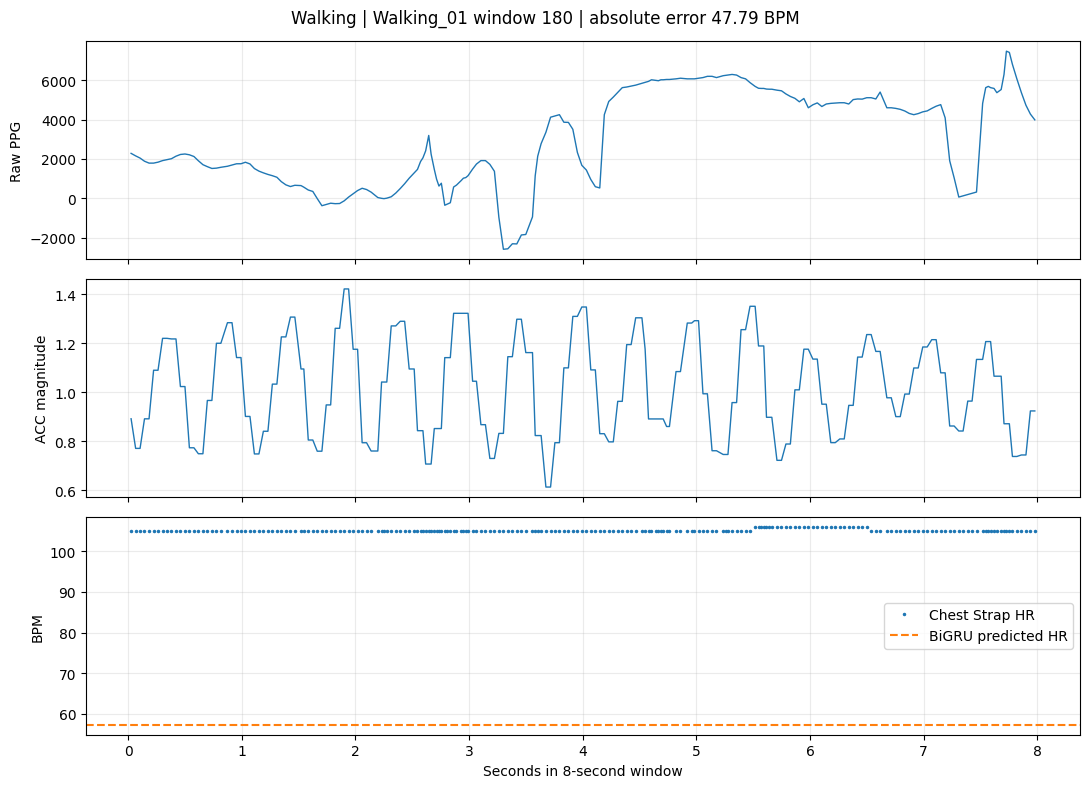

outlier_bigru_test_237.png: raw rows=217, max alignment error=26.0 ms


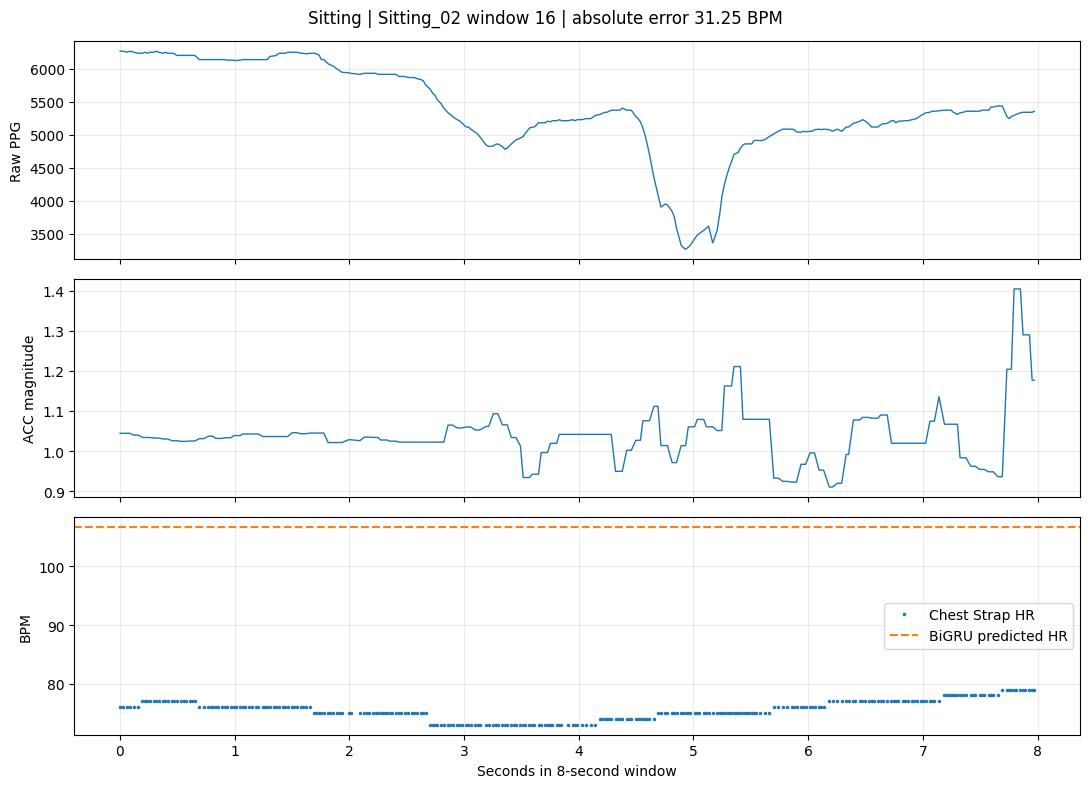

outlier_bigru_test_142.png: raw rows=295, max alignment error=37.0 ms


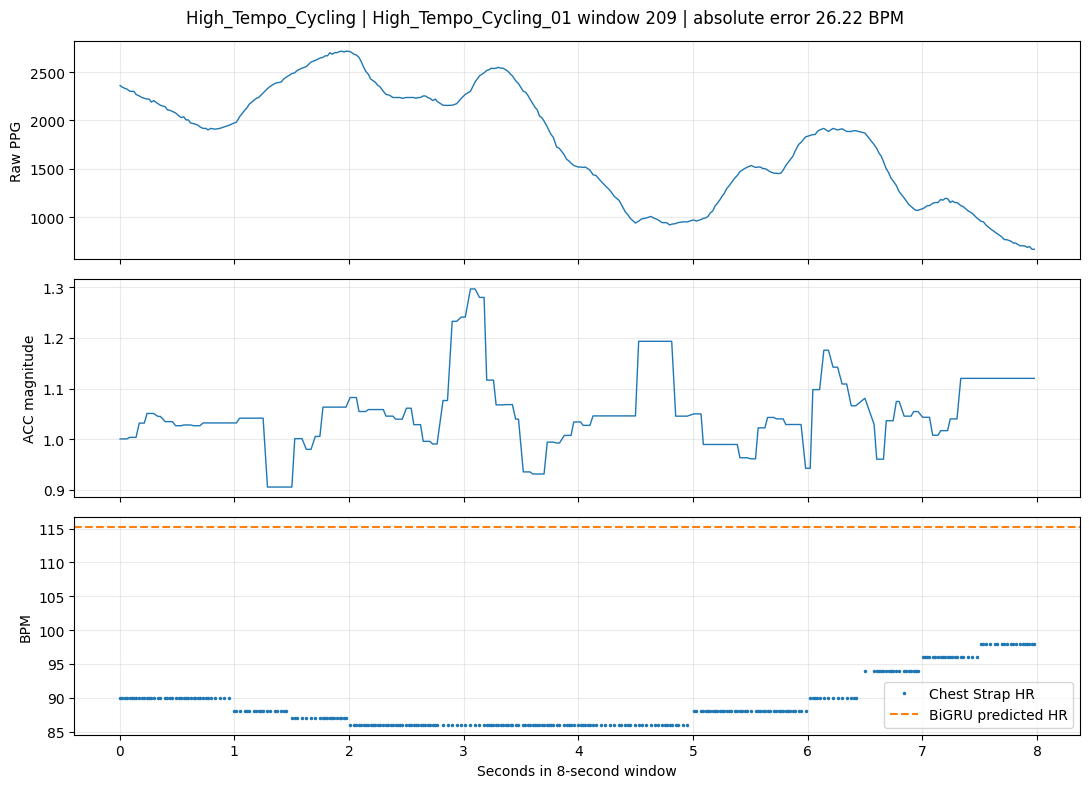

outlier_bigru_test_010.png: raw rows=306, max alignment error=31.0 ms


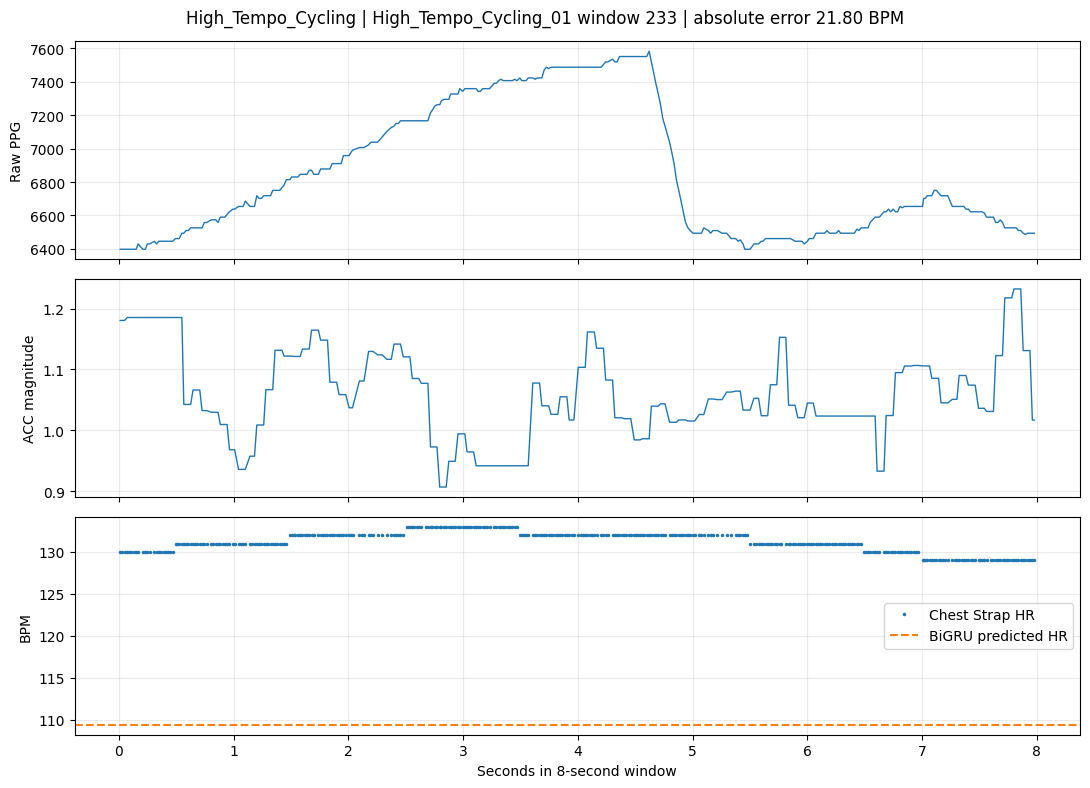

outlier_bigru_test_034.png: raw rows=370, max alignment error=22.0 ms


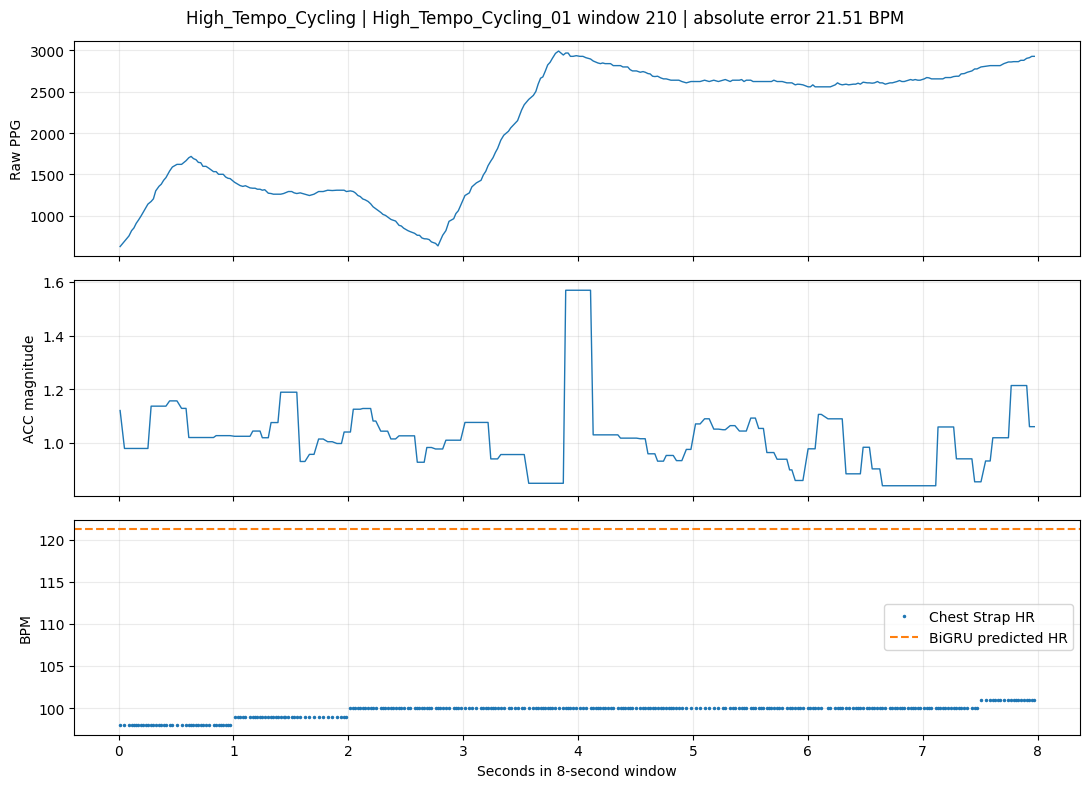

outlier_bigru_test_011.png: raw rows=309, max alignment error=25.0 ms


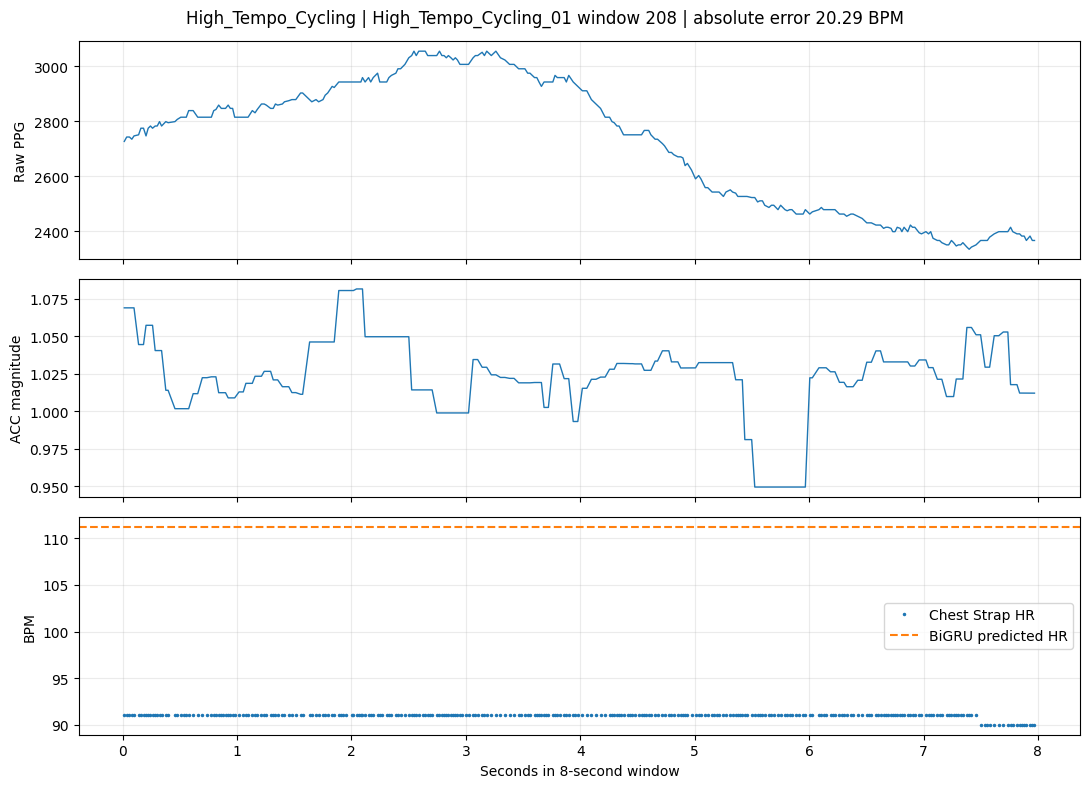

outlier_bigru_test_009.png: raw rows=301, max alignment error=28.0 ms
Saved top-20 outlier table and diagnostic PNGs.


In [3]:
TOP_K = 6
outdir = ROOT / "results/figures"
outdir.mkdir(parents=True, exist_ok=True)
for _, w in verified.nlargest(TOP_K, "Absolute_Error_BPM").iterrows():
    raw = load_session(Path(w["Source_File"]))
    t0, t1 = float(w["Window_Start_ms"]), float(w["Window_End_ms"])
    segment = raw.loc[(raw.Timestamp_ms >= t0) & (raw.Timestamp_ms < t1)].copy()
    t = (segment.Timestamp_ms - t0)/1000
    magnitude = np.sqrt(segment.ACC_X**2 + segment.ACC_Y**2 + segment.ACC_Z**2)
    fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    axes[0].plot(t, segment.PPG_Raw, linewidth=1)
    axes[0].set_ylabel("Raw PPG")
    axes[1].plot(t, magnitude, linewidth=1, label="ACC magnitude")
    axes[1].set_ylabel("ACC magnitude")
    axes[2].plot(t, segment.Chest_HR_BPM, marker=".", linestyle="none", markersize=3, label="Chest Strap HR")
    axes[2].axhline(w["CNN_BiGRU_HR"], color="tab:orange", linestyle="--", label="BiGRU predicted HR")
    axes[2].set_ylabel("BPM")
    axes[2].set_xlabel("Seconds in 8-second window")
    axes[2].legend()
    for ax in axes:
        ax.grid(alpha=.25)
    fig.suptitle(f'{w["Activity"]} | {w["Session_ID"]} window {int(w["Window_ID"])} | absolute error {w["Absolute_Error_BPM"]:.2f} BPM')
    fig.tight_layout()
    name = f'outlier_bigru_test_{int(w["Test_Index"]):03d}.png'
    fig.savefig(outdir / name, dpi=180, bbox_inches="tight")
    plt.show()
    print(f'{name}: raw rows={len(segment)}, max alignment error={w["Max_Time_Error_ms"]:.1f} ms')

verified.nlargest(20, "Absolute_Error_BPM").to_csv(ROOT / "results/metrics/cnn_bigru_top20_outliers.csv", index=False)
print("Saved top-20 outlier table and diagnostic PNGs.")

## Interpretation checklist

- Are errors concentrated in a particular activity/session?
- Is PPG visibly distorted in the same exact 8-second period?
- Does ACC magnitude vary sharply there? **Co-occurrence is not causation.**
- Are there few or repeated chest-strap HR values in the raw window?
- Are timestamp alignment errors high relative to other windows?
- Does the model stay nearly constant while the chest strap changes?

Only report confirmed observations in the README/report; label other possibilities as hypotheses.

In [4]:
walking = verified[verified["Activity"] == "Walking"].copy()

worst = walking.loc[walking["Absolute_Error_BPM"].idxmax()]
best = walking.loc[walking["Absolute_Error_BPM"].idxmin()]

print("WORST WALKING WINDOW")
print(worst[[
    "Test_Index", "Session_ID", "Window_ID",
    "Chest_Strap_HR", "CNN_BiGRU_HR",
    "Absolute_Error_BPM"
]])

print("\nBEST WALKING WINDOW")
print(best[[
    "Test_Index", "Session_ID", "Window_ID",
    "Chest_Strap_HR", "CNN_BiGRU_HR",
    "Absolute_Error_BPM"
]])

WORST WALKING WINDOW
Test_Index                   237
Session_ID            Walking_01
Window_ID                    180
Chest_Strap_HR        105.129036
CNN_BiGRU_HR           57.335354
Absolute_Error_BPM     47.793682
Name: 237, dtype: object

BEST WALKING WINDOW
Test_Index                   264
Session_ID            Walking_02
Window_ID                    271
Chest_Strap_HR        100.599434
CNN_BiGRU_HR          100.539856
Absolute_Error_BPM      0.059578
Name: 264, dtype: object


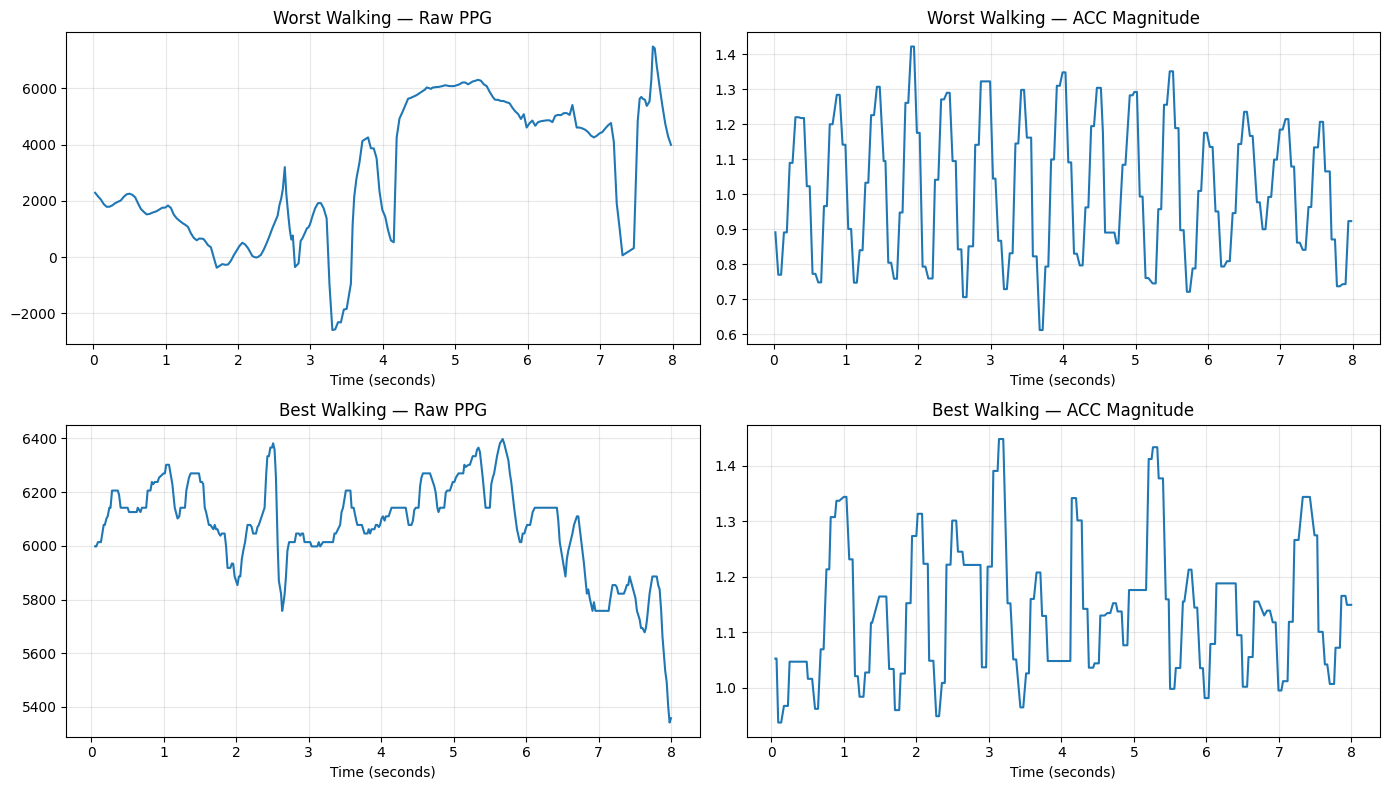

In [6]:
# Compare the best and worst Walking windows
# Uses the existing session loader from notebook 12

from pathlib import Path

DATA_DIR = Path("../data/raw")
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for row_idx, (label, item) in enumerate([
    ("Worst Walking", worst),
    ("Best Walking", best)
]):
    session_id = item["Session_ID"]
    window_id = int(item["Window_ID"])

    # Find the corresponding recording file
    files = list((DATA_DIR / "walking").glob("*.xlsx"))
    file = next(
        f for f in files
        if f.stem.lower() == session_id.lower()
    )

    df = pd.read_excel(file)
    df = df.sort_values("Timestamp_ms").reset_index(drop=True)

    start_ms = df["Timestamp_ms"].iloc[0] + window_id * 8000
    window = df[
        (df["Timestamp_ms"] >= start_ms) &
        (df["Timestamp_ms"] < start_ms + 8000)
    ].copy()

    t = (window["Timestamp_ms"] - start_ms) / 1000

    acc_mag = np.sqrt(
        window["ACC_X"]**2 +
        window["ACC_Y"]**2 +
        window["ACC_Z"]**2
    )

    axes[row_idx, 0].plot(t, window["PPG_Raw"])
    axes[row_idx, 0].set_title(f"{label} — Raw PPG")

    axes[row_idx, 1].plot(t, acc_mag)
    axes[row_idx, 1].set_title(f"{label} — ACC Magnitude")

    for ax in axes[row_idx]:
        ax.set_xlabel("Time (seconds)")
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
# Find sudden prediction drops around test indices 140 and 240

for center in [140, 240]:
    region = verified[
        verified["Test_Index"].between(center - 10, center + 10)
    ].copy()

    region = region.sort_values("Test_Index")

    print(f"\n{'='*55}")
    print(f"TEST INDICES AROUND {center}")
    print(f"{'='*55}")

    print(region[[
        "Test_Index",
        "Activity",
        "Session_ID",
        "Window_ID",
        "Chest_Strap_HR",
        "CNN_BiGRU_HR",
        "Absolute_Error_BPM"
    ]].to_string(index=False))

    lowest = region.loc[region["CNN_BiGRU_HR"].idxmin()]

    print("\nLOWEST PREDICTION IN THIS REGION:")
    print(lowest[[
        "Test_Index",
        "Activity",
        "Session_ID",
        "Window_ID",
        "Chest_Strap_HR",
        "CNN_BiGRU_HR",
        "Absolute_Error_BPM"
    ]])


TEST INDICES AROUND 140
 Test_Index Activity Session_ID  Window_ID  Chest_Strap_HR  CNN_BiGRU_HR  Absolute_Error_BPM
        130  Sitting Sitting_01        244       71.594376     70.987170            0.607206
        131  Sitting Sitting_01        245       74.561950     70.255970            4.305980
        132  Sitting Sitting_01        246       68.032555     70.162674            2.130119
        133  Sitting Sitting_01        247       68.209366     70.113464            1.904098
        134  Sitting Sitting_01        248       67.463806     71.346300            3.882494
        135  Sitting Sitting_01        249       71.513440     71.963870            0.450430
        136  Sitting Sitting_01        250       69.832440     70.806900            0.974460
        137  Sitting Sitting_01        251       71.158600     71.494170            0.335570
        138  Sitting Sitting_01        252       76.077774     72.443054            3.634720
        139  Sitting Sitting_01        253   

In [8]:
point = verified.loc[verified["Test_Index"] == 140].iloc[0]

print("Activity:", point["Activity"])
print("Session:", point["Session_ID"])
print("Window:", point["Window_ID"])
print("Actual HR:", point["Chest_Strap_HR"])
print("Predicted HR:", point["CNN_BiGRU_HR"])
print("Error:", point["Absolute_Error_BPM"])

Activity: Sitting
Session: Sitting_01
Window: 254
Actual HR: 70.27616
Predicted HR: 53.242023
Error: 17.034137


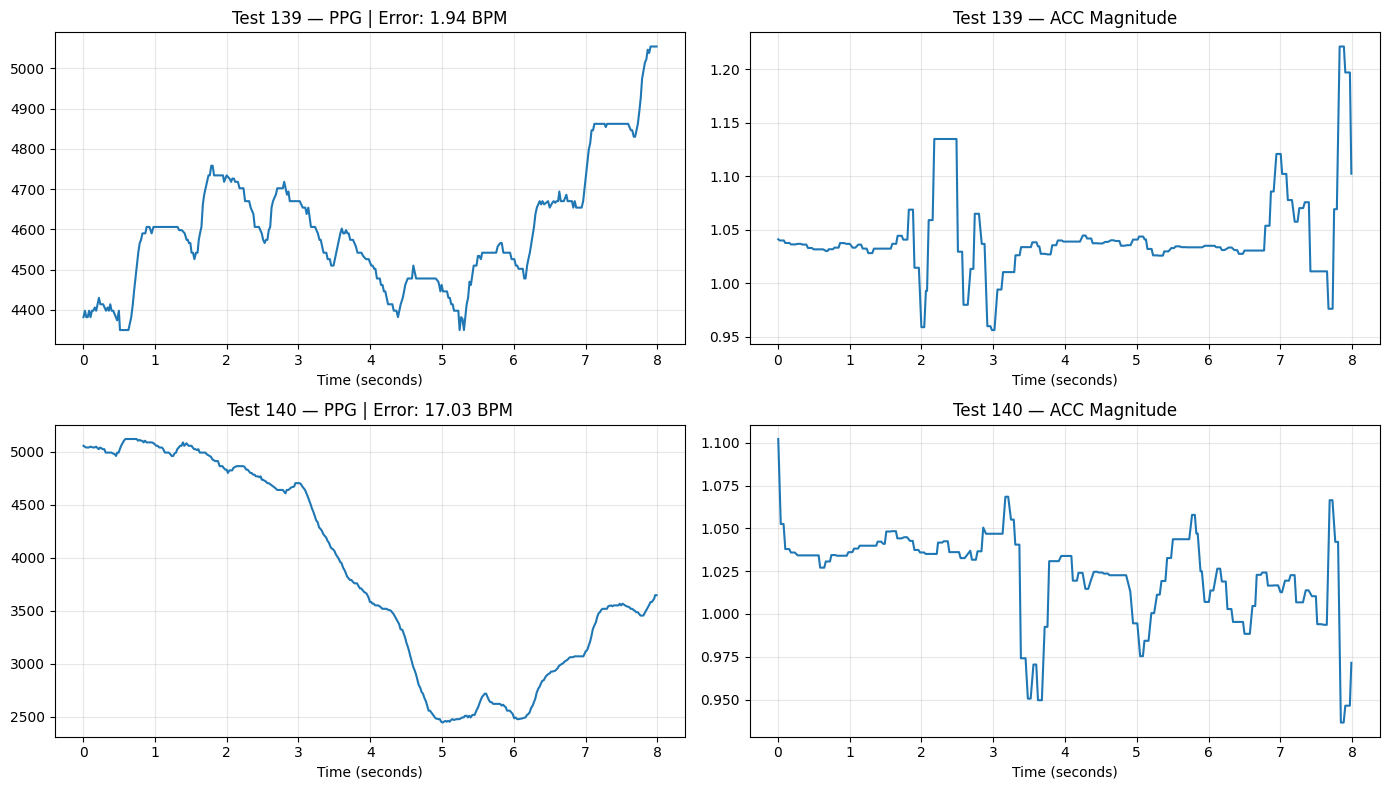

In [9]:
# Compare test windows 139 and 140
from pathlib import Path

file = Path("../data/raw/sitting/Sitting_01.xlsx")
df = pd.read_excel(file).sort_values("Timestamp_ms").reset_index(drop=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for row, test_idx in enumerate([139, 140]):
    point = verified.loc[verified["Test_Index"] == test_idx].iloc[0]

    window_id = int(point["Window_ID"])
    start_ms = df["Timestamp_ms"].iloc[0] + window_id * 8000

    window = df[
        (df["Timestamp_ms"] >= start_ms) &
        (df["Timestamp_ms"] < start_ms + 8000)
    ].copy()

    t = (window["Timestamp_ms"] - start_ms) / 1000

    acc_mag = np.sqrt(
        window["ACC_X"]**2 +
        window["ACC_Y"]**2 +
        window["ACC_Z"]**2
    )

    axes[row, 0].plot(t, window["PPG_Raw"])
    axes[row, 0].set_title(
        f"Test {test_idx} — PPG | Error: "
        f"{point['Absolute_Error_BPM']:.2f} BPM"
    )

    axes[row, 1].plot(t, acc_mag)
    axes[row, 1].set_title(
        f"Test {test_idx} — ACC Magnitude"
    )

    for ax in axes[row]:
        ax.set_xlabel("Time (seconds)")
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

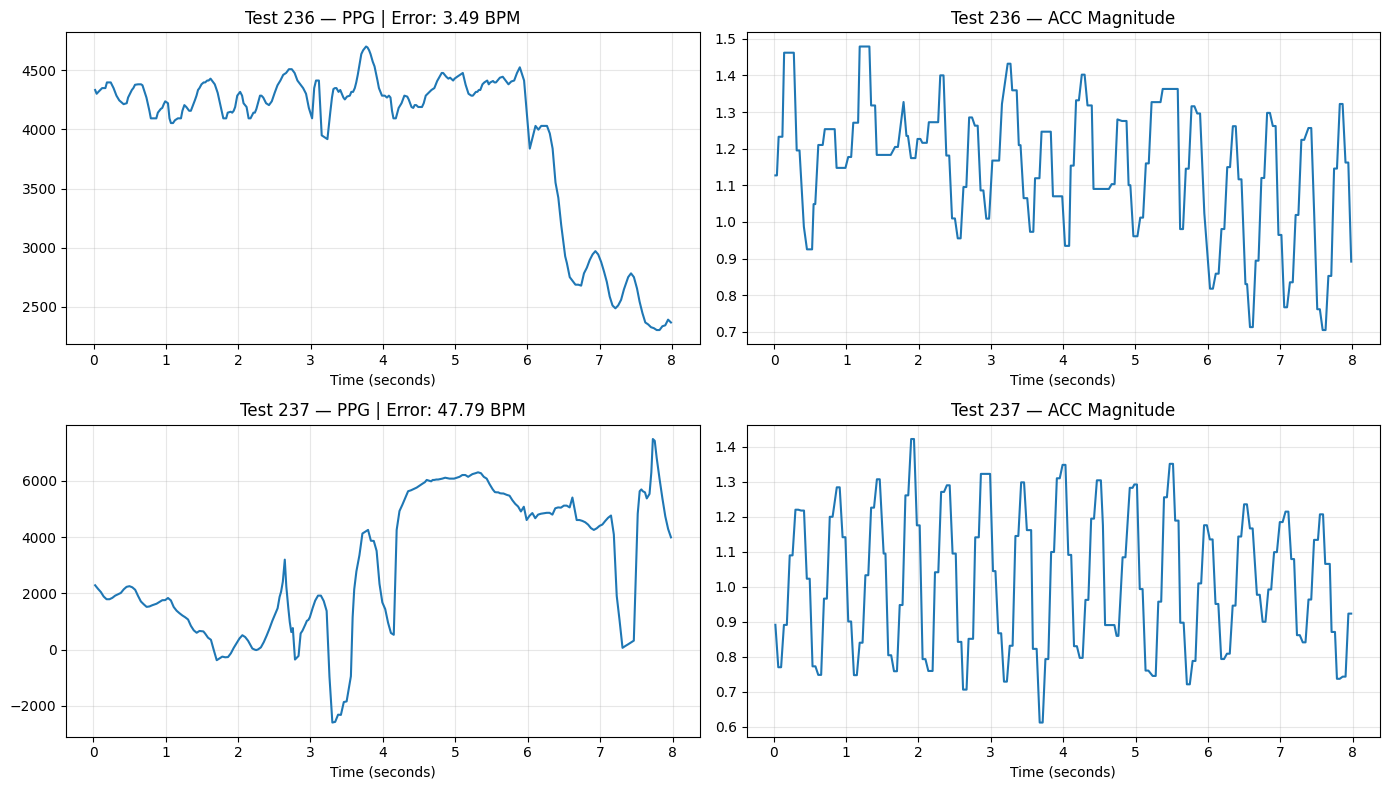

In [10]:
# Compare test windows 236 and 237 (Walking)

from pathlib import Path

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for row, test_idx in enumerate([236, 237]):
    point = verified.loc[
        verified["Test_Index"] == test_idx
    ].iloc[0]

    session_id = point["Session_ID"]
    window_id = int(point["Window_ID"])

    # Read the matching Walking recording
    file = Path("../data/raw/walking") / f"{session_id}.xlsx"

    df = pd.read_excel(file)
    df = df.sort_values("Timestamp_ms").reset_index(drop=True)

    start_ms = df["Timestamp_ms"].iloc[0] + window_id * 8000

    window = df[
        (df["Timestamp_ms"] >= start_ms) &
        (df["Timestamp_ms"] < start_ms + 8000)
    ].copy()

    t = (window["Timestamp_ms"] - start_ms) / 1000

    acc_mag = np.sqrt(
        window["ACC_X"]**2 +
        window["ACC_Y"]**2 +
        window["ACC_Z"]**2
    )

    axes[row, 0].plot(t, window["PPG_Raw"])
    axes[row, 0].set_title(
        f"Test {test_idx} — PPG | "
        f"Error: {point['Absolute_Error_BPM']:.2f} BPM"
    )

    axes[row, 1].plot(t, acc_mag)
    axes[row, 1].set_title(
        f"Test {test_idx} — ACC Magnitude"
    )

    for ax in axes[row]:
        ax.set_xlabel("Time (seconds)")
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()